In [ ]:
import numpy as np
import pandas as pd


np.random.seed(42)

years_of_experience = np.random.randint(2, 21, size=500)

noise = np.random.normal(0, 10000, size=500)

intercept = 60000
slope = (200000 - 60000) / (20 - 2)

salary = intercept + slope * years_of_experience + noise

df = pd.DataFrame({
    'YearsOfExperience': years_of_experience,
    'Salary': salary
})

print("أول 5 صفوف من البيانات:")
print(df.head())
print("\nأبعاد الجدول (Shape):", df.shape)

أول 5 صفوف من البيانات:
   YearsOfExperience         Salary
0                  8  115037.780010
1                 16  182309.972927
2                 12  156442.408989
3                  9  144753.562169
4                  8  130798.818454

أبعاد الجدول (Shape): (500, 2)


--- الإحصائيات الوصفية للبيانات ---
       YearsOfExperience         Salary
count         500.000000     500.000000
mean           10.616000  142570.011096
std             5.662922   44935.263058
min             2.000000   54881.134555
25%             5.750000  104426.300731
50%            10.000000  139865.032545
75%            16.000000  182341.125962
max            20.000000  241879.376204

--- عدد القيم المفقودة ---
YearsOfExperience    0
Salary               0
dtype: int64

--- معامل الارتباط ---
Correlation: 0.975058457607618


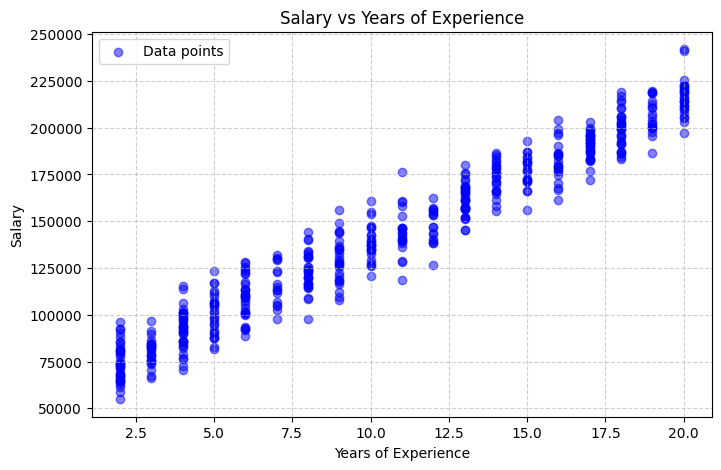

In [ ]:
 import matplotlib.pyplot as plt

print("--- الإحصائيات الوصفية للبيانات ---")
print(df.describe())

print("\n--- عدد القيم المفقودة ---")
print(df.isnull().sum())

print("\n--- معامل الارتباط ---")
correlation = df['YearsOfExperience'].corr(df['Salary'])
print(f"Correlation: {correlation}")

plt.figure(figsize=(8, 5))
plt.scatter(df['YearsOfExperience'], df['Salary'], color='blue', alpha=0.5, label='Data points')
plt.title('Salary vs Years of Experience')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

In [ ]:
 from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X = df[['YearsOfExperience']]
y = df['Salary']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"حجم بيانات التدريب (X_train): {X_train.shape}")
print(f"حجم بيانات الاختبار (X_test): {X_test.shape}")

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

print(f"\nالميل (Slope): {lr_model.coef_[0]}")
print(f"نقطة التقاطع (Intercept): {lr_model.intercept_}")

train_r2 = lr_model.score(X_train, y_train)
test_r2 = lr_model.score(X_test, y_test)
print(f"Training R2: {train_r2}")
print(f"Test R2: {test_r2}")

y_pred = lr_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f"\nEvaluation Metrics:")
print(f"MAE: {mae}")
print(f"MSE: {mse}")
print(f"RMSE: {rmse}")

print("\nعينة لـ 5 قيم حقيقية مقابل المتوقعة:")
comparison_df = pd.DataFrame({'Actual': y_test.values[:5], 'Predicted': y_pred[:5]})
print(comparison_df)

حجم بيانات التدريب (X_train): (400, 1)
حجم بيانات الاختبار (X_test): (100, 1)

الميل (Slope): 7696.612923052044
نقطة التقاطع (Intercept): 60961.340880280564
Training R2: 0.9488372177019488
Test R2: 0.9573704756930141

Evaluation Metrics:
MAE: 7905.114728709239
MSE: 93933277.37947103
RMSE: 9691.918147584152

عينة لـ 5 قيم حقيقية مقابل المتوقعة:
          Actual      Predicted
0  123631.230350  107141.018419
1  139775.630647  122534.244265
2   93184.812446  107141.018419
3  166740.803478  161017.308880
4  174587.183981  184107.147649


--- مقارنة النموذج مع النموذج الأساسي (Baseline) ---
Baseline MAE: 40444.95787424255
Baseline RMSE: 46953.769510036946
Linear Reg MAE: 7905.114728709239
Linear Reg RMSE: 9691.918147584152


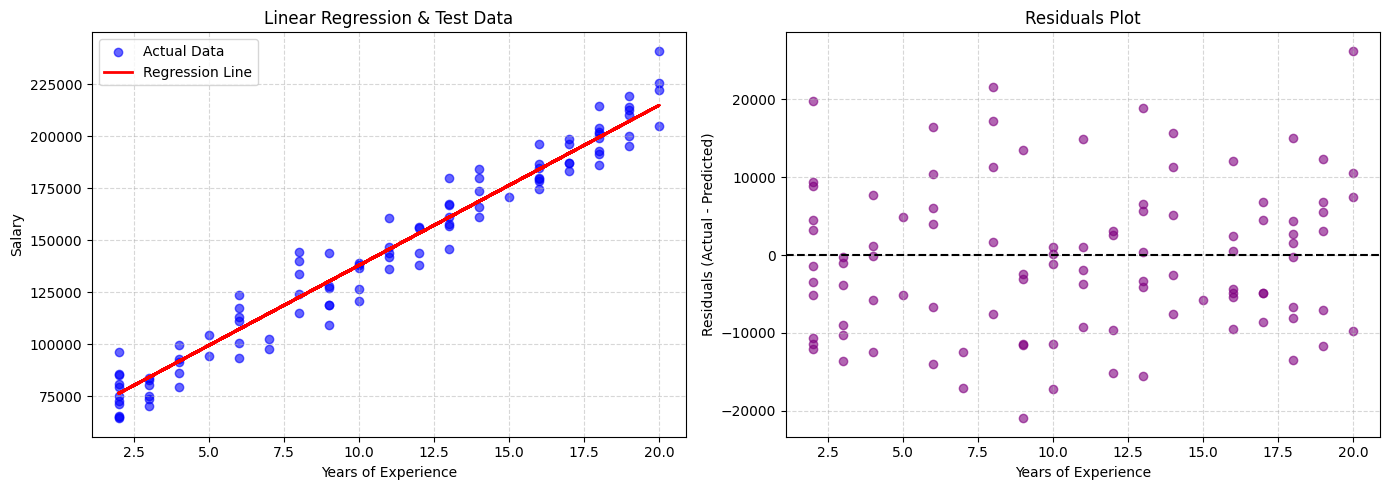


--- التنبؤ برواتب جديدة (Task 9) ---
   YearsOfExperience  Predicted_Salary
0                  5      99444.405496
1                 10     137927.470111
2                 15     176410.534726


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [ ]:
baseline_pred = np.full_like(y_test, y_train.mean())
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))

print("--- مقارنة النموذج مع النموذج الأساسي (Baseline) ---")
print(f"Baseline MAE: {baseline_mae}")
print(f"Baseline RMSE: {baseline_rmse}")
print(f"Linear Reg MAE: {mae}")
print(f"Linear Reg RMSE: {rmse}")


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(X_test, y_test, color='blue', alpha=0.6, label='Actual Data')
axes[0].plot(X_test, y_pred, color='red', linewidth=2, label='Regression Line')
axes[0].set_title('Linear Regression & Test Data')
axes[0].set_xlabel('Years of Experience')
axes[0].set_ylabel('Salary')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

residuals = y_test - y_pred
axes[1].scatter(X_test, residuals, color='purple', alpha=0.6)
axes[1].axhline(0, color='black', linestyle='--', linewidth=1.5)
axes[1].set_title('Residuals Plot')
axes[1].set_xlabel('Years of Experience')
axes[1].set_ylabel('Residuals (Actual - Predicted)')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


new_experience = np.array([[5], [10], [15]])
new_salaries = lr_model.predict(new_experience)

print("\n--- التنبؤ برواتب جديدة (Task 9) ---")
new_pred_df = pd.DataFrame({
    'YearsOfExperience': [5, 10, 15],
    'Predicted_Salary': new_salaries
})
print(new_pred_df)

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("--- نتائج نموذج Ridge ---")
for alpha in [10, 100]:
    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train_scaled, y_train)
    y_pred_ridge = ridge.predict(X_test_scaled)
    mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
    r2_ridge = r2_score(y_test, y_pred_ridge)
    print(f"Alpha: {alpha} | Coefficient: {ridge.coef_[0]:.4f} | MAE: {mae_ridge:.4f} | R2: {r2_ridge:.4f}")

ridge_final = Ridge(alpha=10)
ridge_final.fit(X_train_scaled, y_train)
y_pred_ridge_final = ridge_final.predict(X_test_scaled)


print("\n--- نتائج نموذج Lasso ---")
for alpha in [1000, 10000, 50000]:
    lasso = Lasso(alpha=alpha, max_iter=20000)
    lasso.fit(X_train_scaled, y_train)
    y_pred_lasso = lasso.predict(X_test_scaled)
    mae_lasso = mean_absolute_error(y_test, y_pred_lasso)
    r2_lasso = r2_score(y_test, y_pred_lasso)
    print(f"Alpha: {alpha} | Coefficient: {lasso.coef_[0]:.4f} | MAE: {mae_lasso:.4f} | R2: {r2_lasso:.4f}")

lasso_final = Lasso(alpha=1000, max_iter=20000)
lasso_final.fit(X_train_scaled, y_train)
y_pred_lasso_final = lasso_final.predict(X_test_scaled)


comparison_data = {
    'Model': ['Baseline', 'Linear Regression', 'Ridge (alpha=10)', 'Lasso (alpha=1000)'],
    'MAE': [
        mean_absolute_error(y_test, baseline_pred),
        mean_absolute_error(y_test, y_pred),
        mean_absolute_error(y_test, y_pred_ridge_final),
        mean_absolute_error(y_test, y_pred_lasso_final)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test, baseline_pred)),
        np.sqrt(mean_squared_error(y_test, y_pred)),
        np.sqrt(mean_squared_error(y_test, y_pred_ridge_final)),
        np.sqrt(mean_squared_error(y_test, y_pred_lasso_final))
    ],
    'R2': [
        r2_score(y_test, baseline_pred),
        r2_score(y_test, y_pred),
        r2_score(y_test, y_pred_ridge_final),
        r2_score(y_test, y_pred_lasso_final)
    ]
}

comparison_table = pd.DataFrame(comparison_data)
print("\n--- جدول المقارنة النهائي (Task 13) ---")
print(comparison_table.to_string(index=False))

print("\n--- الخلاصة (Conclusion) ---")
print("1. أظهرت النماذج المتقدمة (الانحدار الخطي، ريدج، ولاسو) تفوقاً ملحوظاً وأداءً أفضل بكثير مقارنة بالنموذج الأساسي (Baseline).")
print("2. تقارب أداء نماذج الانحدار الخطي وريدج ولاسو نظراً لأن العلاقة الأساسية بين البيانات خطية وواضحة.")

--- نتائج نموذج Ridge ---
Alpha: 10 | Coefficient: 42156.5031 | MAE: 8084.4613 | R2: 0.9557
Alpha: 100 | Coefficient: 34568.3325 | MAE: 11308.3700 | R2: 0.9118

--- نتائج نموذج Lasso ---
Alpha: 1000 | Coefficient: 42210.4157 | MAE: 8074.6515 | R2: 0.9558
Alpha: 10000 | Coefficient: 33210.4157 | MAE: 12287.9627 | R2: 0.8980
Alpha: 50000 | Coefficient: 0.0000 | MAE: 40444.9579 | R2: -0.0005

--- جدول المقارنة النهائي (Task 13) ---
             Model          MAE         RMSE        R2
          Baseline 40444.957874 46953.769510 -0.000534
 Linear Regression  7905.114729  9691.918148  0.957370
  Ridge (alpha=10)  8084.461348  9876.931577  0.955727
Lasso (alpha=1000)  8074.651463  9864.608230  0.955838

--- الخلاصة (Conclusion) ---
1. أظهرت النماذج المتقدمة (الانحدار الخطي، ريدج، ولاسو) تفوقاً ملحوظاً وأداءً أفضل بكثير مقارنة بالنموذج الأساسي (Baseline).
2. تقارب أداء نماذج الانحدار الخطي وريدج ولاسو نظراً لأن العلاقة الأساسية بين البيانات خطية وواضحة.
